In [2]:
import alphashape
import numpy as np
import regionmask
import xarray as xr

mesh_nc = xr.open_dataset("inputs/UGdcsm-fm_100m2coast3d_v3_era5bnd_net.nc")
alpha_shape = alphashape.alphashape(
    np.column_stack([mesh_nc.mesh2d_node_x.values, mesh_nc.mesh2d_node_y.values])[
        ::5, :
    ],
    10,
)
my_region = regionmask.Regions([alpha_shape], name="my_region")
my_region

<regionmask.Regions 'my_region'>
overlap:  None

Regions:
0 r0 Region0

[1 regions]

In [3]:
mesh_nc

<xarray.Dataset> Size: 139MB
Dimensions:                  (mesh2d_nNodes: 338292, mesh2d_nEdges: 678547,
                              Two: 2, mesh2d_nFaces: 340254,
                              mesh2d_nMax_face_nodes: 4, nNetElem: 340254,
                              nNetElemMaxNode: 4, nNetLink: 678547,
                              nmesh2d_NetLinkContourPts: 4)
Coordinates:
    mesh2d_node_x            (mesh2d_nNodes) float64 3MB 3.548 3.547 ... 4.609
    mesh2d_node_y            (mesh2d_nNodes) float64 3MB 51.4 51.4 ... 52.61
    mesh2d_edge_x            (mesh2d_nEdges) float64 5MB ...
    mesh2d_edge_y            (mesh2d_nEdges) float64 5MB ...
Dimensions without coordinates: mesh2d_nNodes, mesh2d_nEdges, Two,
                                mesh2d_nFaces, mesh2d_nMax_face_nodes,
                                nNetElem, nNetElemMaxNode, nNetLink,
                                nmesh2d_NetLinkContourPts
Data variables: (12/16)
    wgs84                    int32 4B ...
    mesh2d                   int32 4B ...
    mesh2d_node_z            (mesh2d_nNodes) float64 3MB ...
    mesh2d_edge_nodes        (mesh2d_nEdges, Two) int32 5MB ...
    mesh2d_face_nodes        (mesh2d_nFaces, mesh2d_nMax_face_nodes) float64 11MB ...
    mesh2d_face_x            (mesh2d_nFaces) float64 3MB ...
    ...                       ...
    NetElemNode              (nNetElem, nNetElemMaxNode) float64 11MB ...
    NetElemLink              (nNetElem, nNetElemMaxNode) int32 5MB ...
    mesh2d_NetLinkContour_x  (nNetLink, nmesh2d_NetLinkContourPts) float64 22MB ...
    mesh2d_NetLinkContour_y  (nNetLink, nmesh2d_NetLinkContourPts) float64 22MB ...
    NetLink_xu               (nNetLink) float64 5MB ...
    NetLink_yu               (nNetLink) float64 5MB ...
Attributes:
    institution:    Deltares
    references:     https://www.deltares.nl
    source:         D-Flow FM 1.2.184.Unknown. Model:
    history:        Created on 2024-11-24T21:38:05+0100, D-Flow FM
    date_created:   2024-11-24T21:38:05+0100
    date_modified:  2024-11-24T21:38:05+0100
    Conventions:    CF-1.8 UGRID-1.0 Deltares-0.10
    uuid:           d546913e-2cfd-1148-9c51-a2126ace7cca

In [2]:
goals_config = {
    1: {"lon": 7.0, "lat": 54.0, "angles": [-70, 180]},
    2: {"lon": 6.5, "lat": 54.0, "angles": [0, 180]},
    3: {"lon": 6.0, "lat": 54.0, "angles": [0, 180]},
    4: {"lon": 5.5, "lat": 54.0, "angles": [0, 180]},
    5: {"lon": 5.0, "lat": 54.0, "angles": [0, 225]},
    6: {"lon": 4.5, "lat": 53.5, "angles": [45, 225]},
    7: {"lon": 4.0, "lat": 53.0, "angles": [45, 225]},
    8: {"lon": 3.5, "lat": 52.5, "angles": [45, 225]},
    9: {"lon": 3.0, "lat": 52.0, "angles": [45, 225]},
    10: {"lon": 2.5, "lat": 51.5, "angles": [45, 310]},
}
goals_config.keys()

dict_keys([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])

In [3]:
import pandas as pd

dynamic_cases_ds_201106 = (
    xr.open_dataset("inputs/ERA5_forcing_goals_2000_2025.nc")
    .sel(time="2011-06")[
        [
            "swh",
            "pp1d",
            "mwd",
            "wdw",
        ]
    ]
    .rename({"swh": "hs", "pp1d": "tp", "mwd": "wd", "wdw": "ds"})
)
dynamic_cases_ds_201112 = (
    xr.open_dataset("inputs/ERA5_forcing_goals_2000_2025.nc")
    .sel(time="2011-12")[
        [
            "swh",
            "pp1d",
            "mwd",
            "wdw",
        ]
    ]
    .rename({"swh": "hs", "pp1d": "tp", "mwd": "wd", "wdw": "ds"})
)
dynamic_cases_ds = xr.concat(
    [dynamic_cases_ds_201106, dynamic_cases_ds_201112], dim="time"
)

metamodel_parameters = {
    "hs_goals": [
        dynamic_cases_ds.hs.isel(time=itime).values.tolist()
        for itime in range(len(dynamic_cases_ds.time))
    ],
    "tp_goals": [
        dynamic_cases_ds.tp.isel(time=itime).values.tolist()
        for itime in range(len(dynamic_cases_ds.time))
    ],
    "wd_goals": [
        dynamic_cases_ds.wd.isel(time=itime).values.tolist()
        for itime in range(len(dynamic_cases_ds.time))
    ],
    "ds_goals": [
        dynamic_cases_ds.ds.isel(time=itime).values.tolist()
        for itime in range(len(dynamic_cases_ds.time))
    ],
    "tref": pd.to_datetime(dynamic_cases_ds.time.values)
    .strftime("%Y%m%d %H%M%S")
    .tolist(),
}
metamodel_parameters.keys()

dict_keys(['hs_goals', 'tp_goals', 'wd_goals', 'ds_goals', 'tref'])

In [4]:
from bluemath_tk.wrappers.snapwave.snapwave_wrapper import SnapWaveModelWrapper

snapwave_wrapper = SnapWaveModelWrapper(
    templates_dir="templates-era5",
    metamodel_parameters=metamodel_parameters,
    fixed_parameters={},
    output_dir="SnapWave_CASES_ERA5_Dynamic",
    region_of_interest=my_region,
    goals_config=goals_config,
)
snapwave_wrapper

2026-04-15 11:28:26,999 - SnapWaveModelWrapper - WARNING - Parameter hs_goals is not in the default_parameters
2026-04-15 11:28:27,000 - SnapWaveModelWrapper - WARNING - Parameter tp_goals is not in the default_parameters
2026-04-15 11:28:27,000 - SnapWaveModelWrapper - WARNING - Parameter wd_goals is not in the default_parameters
2026-04-15 11:28:27,000 - SnapWaveModelWrapper - WARNING - Parameter ds_goals is not in the default_parameters
2026-04-15 11:28:27,001 - SnapWaveModelWrapper - WARNING - Parameter tref is not in the default_parameters


In [5]:
snapwave_wrapper.calculate_output_grid_parameters(output_grid_resolution=0.01)

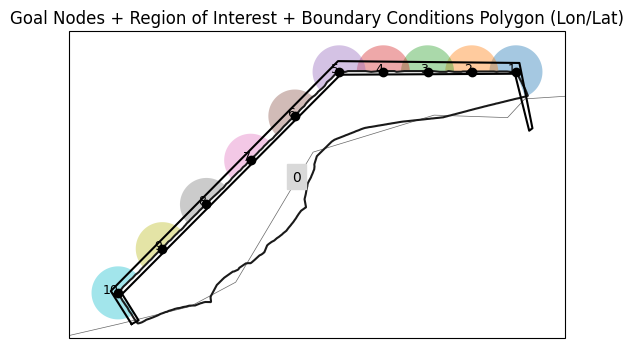

In [6]:
snapwave_wrapper.plot_configuration()

In [ ]:
snapwave_wrapper.build_cases(cases_name_format=lambda ctx: f"{ctx.get('tref')}")

In [8]:
# snapwave_wrapper.run_cases_in_background(launcher="default", num_workers=5)

In [9]:
snapwave_wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    1464
Name: count, dtype: int64

In [10]:
result = snapwave_wrapper.postprocess_cases()
result

<xarray.Dataset> Size: 330kB
Dimensions:       (time: 1464, stations: 9)
Coordinates:
  * time          (time) datetime64[ns] 12kB 2011-06-01 ... 2011-12-31T23:00:00
    station_name  (stations) |S256 2kB b'8851                            ' .....
    station_x     (stations) float32 36B 5.481 5.484 4.66 ... 4.996 6.367 4.158
    station_y     (stations) float32 36B 53.51 53.51 53.28 ... 53.32 53.62 52.05
    point_zb      (stations) float32 36B nan nan nan nan nan nan nan nan nan
Dimensions without coordinates: stations
Data variables:
    point_zs      (time, stations) float32 53kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    point_hm0     (time, stations) float32 53kB 0.6849 0.6851 ... 0.6943 1.021
    point_tp      (time, stations) float32 53kB 4.764 4.764 ... 4.775 4.775
    point_wavdir  (time, stations) float32 53kB 328.0 328.0 ... 279.9 269.6
    point_dw      (time, stations) float32 53kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    point_df      (time, stations) float32 53kB 2.699e-05 2.511e-05 ... 0.005733
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

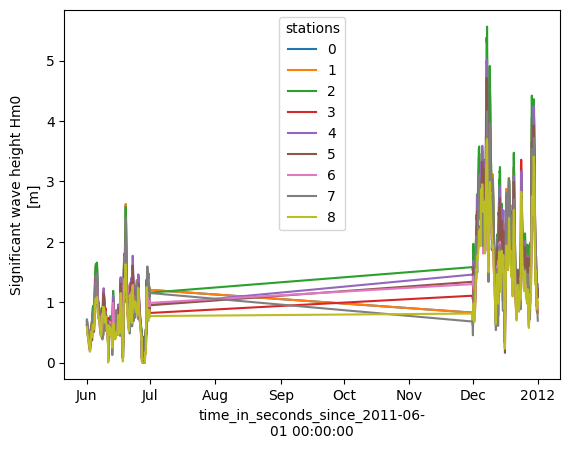

In [11]:
result.point_hm0.plot(hue="stations")

In [12]:
result.to_netcdf("outputs/Dynamic_Cases_201106_201112.nc")